# 8-4. p,d 조인트 그리드서치로 최종 파라미터 확정

d,p ∈ {0,1,2} 9개 조합 x 세 모델 x 22개 origin을 커버리지·MSE·CRPS(정규분포)로 비교하고, (d,p)별 순위를 합산해 최종 (d,p)를 정한다. 모델 함수는 `8-2`와 같다. `8-1`, `8-3`은 이 그리드가 필요한 이유를 보여주는 앞 단계다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats
from scipy.optimize import minimize

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
MODEL_NAMES = ["AR단독", "GARCH동시", "SV동시"]

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개")


채점 origin 22개


## 1. 수정된 세 모델 함수

`8-2`와 같은 코드다(노트북 하나로 완결되게 다시 정의했다). `level_sigma`가 모든 (d,p)에서 정확한 다단계 σ를 계산하고, 세 모델 모두 드리프트가 없다. p=0이면 GARCH는 평균 0(`ZeroMean`), SV는 AR항 없음이다.


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차: 오차 eps_(t+i)가 psi_(h-i)배로 쌓인다
    # (psi = AR 충격반응을 d번 누적합). innov_var[i] = (i+1)단계 오차분산 예측.
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def ar_forecast(train, d, p):
    m = pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    par = dict(zip(m.arima_res_.model.param_names, m.arima_res_.params))
    ar = [par[f"ar.L{k}"] for k in range(1, p + 1)]
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z), {"ar1": ar[0] if p else np.nan}


def garch_forecast(train, d, p):
    diff_train, hist = difference(train, d)
    if len(diff_train) <= p + 3:
        return None
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    try:
        res = am.fit(disp="off")
    except Exception:
        return None
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, d)
    sig = level_sigma(ar, d, f.residual_variance.values[-1])
    return fc, sig, {"ar1": ar[0] if p else np.nan, "omega": res.params["omega"], "alpha": res.params["alpha[1]"], "beta": res.params["beta[1]"]}


def sv_forecast(train, d, p):
    y, hist = difference(train, d)
    if len(y) <= p + 3:
        return None
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2)
         for k in range(1, H + 1)]
    return undiff_mean(mean_diff, hist, d), level_sigma(ar, d, v), {"ar1": ar[0] if p else np.nan, "phi_logvol": phi, "sigma_eta": np.sqrt(s2)}


FORECASTERS = {"AR단독": ar_forecast, "GARCH동시": garch_forecast, "SV동시": sv_forecast}


def run(d, p):
    rows, infos = [], []
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in FORECASTERS.items():
            try:
                out = fn(train, d, p)
            except Exception:
                out = None
            if out is None:
                continue
            fc, sig, info = out
            infos.append({"d": d, "p": p, "모델": name, "origin": origin, **info})
            for h in range(H):
                rows.append({"d": d, "p": p, "모델": name, "origin": origin, "h": h + 1, "fc": fc[h],
                             "sigma": max(sig[h], 1e-6), "actual": actual[h]})
    return pd.DataFrame(rows), pd.DataFrame(infos)


def add_scores(df):
    df = df.copy()
    df["z"] = (df["actual"] - df["fc"]) / df["sigma"]
    df["cov"] = (df["z"].abs() <= Z) * 100.0
    df["mse"] = ((df["actual"] - df["fc"]) / var_std) ** 2
    df["crps"] = ps.crps_gaussian(df["actual"], mu=df["fc"], sig=df["sigma"]) / var_std
    return df


def summarize(df, keys=("모델",)):
    return df.groupby(list(keys)).agg(커버리지=("cov", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean")).round(3)


## 2. Walk-forward -- 9개 (d,p) 조합 x 모델 3종 x 22개 origin

결과를 캐시에 저장한다.


In [3]:
D_CANDIDATES, P_CANDIDATES = [0, 1, 2], [0, 1, 2]
CACHE_PATH = "../cache/cache_84_fixed_dp_grid_df.pkl"

if os.path.exists(CACHE_PATH):
    grid = pd.read_pickle(CACHE_PATH)
    print(f"캐시에서 로드: {len(grid)}행 (재계산 스킵)")
else:
    grid = pd.concat([add_scores(run(d, p)[0]) for d in D_CANDIDATES for p in P_CANDIDATES], ignore_index=True)
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    grid.to_pickle(CACHE_PATH)
    print(f"새로 계산 후 캐시 저장: {len(grid)}행")


캐시에서 로드: 2376행 (재계산 스킵)


## 3. 결과 -- 커버리지/MSE/CRPS


In [4]:
new = summarize(grid, ("d", "p", "모델"))
display(new)


커버리지     MSE   CRPS
d p 모델                             
0 0 AR단독      63.636   8.806  1.849
    GARCH동시   88.636   8.806  1.721
    SV동시     100.000   8.806  1.730
  1 AR단독      59.091   1.065  0.579
    GARCH동시   72.727   1.075  0.588
    SV동시      96.591   8.599  1.633
  2 AR단독      63.636   1.158  0.593
    GARCH동시   73.864   1.130  0.595
    SV동시      96.591  12.071  1.930
1 0 AR단독      59.091   1.040  0.579
    GARCH동시   72.727   1.040  0.577
    SV동시      70.455   1.040  0.568
  1 AR단독      65.909   1.128  0.593
    GARCH동시   73.864   1.080  0.582
    SV동시      64.773   1.052  0.578
  2 AR단독      68.182   1.076  0.577
    GARCH동시   71.591   1.118  0.601
    SV동시      64.773   1.051  0.580
2 0 AR단독      63.636   2.625  0.891
    GARCH동시   81.818   2.625  0.867
    SV동시      69.318   2.625  0.895
  1 AR단독      59.091   2.445  0.873
    GARCH동시   69.318   2.435  0.844
    SV동시      56.818   2.551  0.898
  2 AR단독      55.682   2.205  0.839
    GARCH동시   68.182   2.264  0.832
    SV동시      57.955   2.723  0.928

## 4. 순위 합산 -- (d,p) 조합별 종합 순위

모델 3종 x 지표 3종 = 9칸마다 (d,p) 9개 조합의 순위를 매겨 합산한다(커버리지는 90%에서 먼 정도, MSE/CRPS는 낮을수록 좋은 쪽).


In [5]:
def rank_sum(summary_df):
    parts = []
    for m in MODEL_NAMES:
        sub = summary_df.xs(m, level="모델")
        parts.append(pd.DataFrame({"커버리지순위": (sub["커버리지"] - 90).abs().rank(), "MSE순위": sub["MSE"].rank(), "CRPS순위": sub["CRPS"].rank()}))
    rs = sum(parts)
    rs["합계"] = rs.sum(axis=1)
    return rs.sort_values("합계")


display(rank_sum(new))


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    16.5    3.0     4.5  24.0
  1    12.0   10.0     8.5  30.5
  2    14.5    9.0     9.0  32.5
0 1    14.0   11.0    12.5  37.5
  2     9.0   19.0    17.5  45.5
2 0    11.0   21.0    20.0  52.0
0 0     8.0   26.0    26.0  60.0
2 1    24.0   18.0    19.0  61.0
  2    26.0   18.0    18.0  62.0

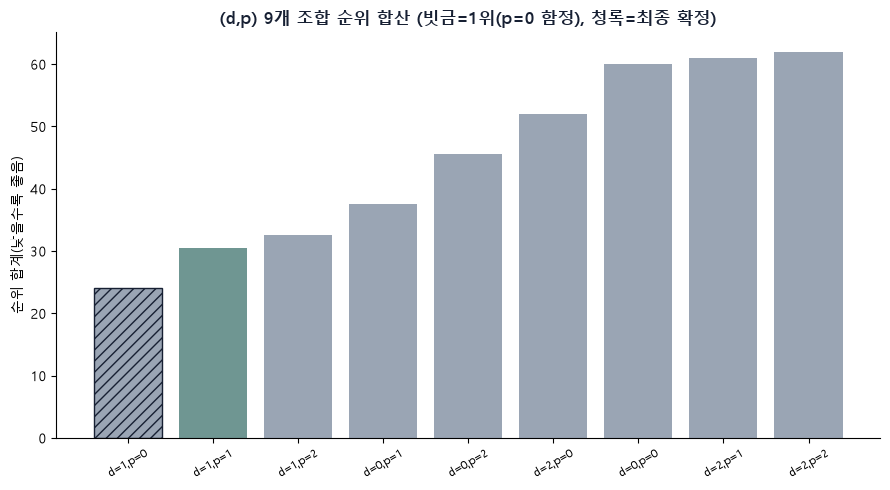

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

rs = rank_sum(new)
labels = [f"d={d},p={p}" for d, p in rs.index]
bar_colors = ["#6F9692" if (d, p) == (1, 1) else "#9AA5B4" for d, p in rs.index]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, rs["합계"], color=bar_colors)
bars[0].set_hatch("///")
bars[0].set_edgecolor("#172033")
ax.set_ylabel("순위 합계(낮을수록 좋음)")
ax.set_title("(d,p) 9개 조합 순위 합산 (빗금=1위(p=0 함정), 청록=최종 확정)", fontsize=12, fontweight="bold", color="#172033")
ax.tick_params(axis="x", rotation=30, labelsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 5. 함정 점검 -- p=0과 d=0

- **p=0(랜덤워크)**: 평균식에 AR항이 없으면 세 모델의 점예측이 똑같아져서(MSE 동일) GARCH/SV를 동시에 추정하는 효과를 점예측에서 볼 수 없다. **정확도가 나빠서가 아니라 연구 질문(동시최적화가 점예측을 바꾸는가)에 답할 수 없어서** 제외한다. 실제로 p=0의 정확도는 가장 좋다.
- **d=0**: SV동시가 무너진다(아래 표).


In [7]:
trap = new.reset_index()
p0 = trap[trap["p"] == 0].pivot_table(index="d", columns="모델", values="MSE")
print("p=0: 세 모델의 MSE (같으면 점예측이 100% 동일해 동시최적화 효과를 볼 수 없는 조합)")
display(p0)
d0 = trap[(trap["d"] == 0) & (trap["p"] > 0)]
print("d=0, p>0:")
display(d0.set_index(["d", "p", "모델"]))


p=0: 세 모델의 MSE (같으면 점예측이 100% 동일해 동시최적화 효과를 볼 수 없는 조합)


모델,AR단독,GARCH동시,SV동시
d,,,
0,8.806,8.806,8.806
1,1.040,1.040,1.040
2,2.625,2.625,2.625


d=0, p>0:


커버리지     MSE   CRPS
d p 모델                            
0 1 AR단독     59.091   1.065  0.579
    GARCH동시  72.727   1.075  0.588
    SV동시     96.591   8.599  1.633
  2 AR단독     63.636   1.158  0.593
    GARCH동시  73.864   1.130  0.595
    SV동시     96.591  12.071  1.930

## 6. 충격 origin 제외 민감도

22개 origin은 겹치는 예측구간이라 유효표본이 작아, 소수의 충격 구간이 순위를 좌우할 수 있다. d=1,p=1에서 AR단독의 제곱오차 합이 가장 큰 origin 2개(충격 구간)를 뺀 뒤 (d,p) 순위합산과 세 모델 성능이 유지되는지 본다.


In [8]:
oe = grid[(grid["d"] == 1) & (grid["p"] == 1) & (grid["모델"] == "AR단독")].groupby("origin")["mse"].sum()
shock = list(oe.sort_values(ascending=False).index[:2])
print("제외한 충격 origin:", shock, "(전체 AR단독 제곱오차 합 중 비중 %.1f%%)" % (100 * oe[shock].sum() / oe.sum()))
g2 = grid[~grid["origin"].isin(shock)]
new2 = summarize(g2, ("d", "p", "모델"))
print("d=1, p=1 성능 -- 전체 vs 충격 제외")
display(summarize(grid[(grid["d"] == 1) & (grid["p"] == 1)]).join(summarize(g2[(g2["d"] == 1) & (g2["p"] == 1)]), lsuffix="_전체", rsuffix="_제외"))
print("(d,p) 순위합산 -- 충격 제외")
display(rank_sum(new2))


제외한 충격 origin: [47, 46] (전체 AR단독 제곱오차 합 중 비중 50.4%)
d=1, p=1 성능 -- 전체 vs 충격 제외


,커버리지_전체,MSE_전체,CRPS_전체,커버리지_제외,MSE_제외,CRPS_제외
모델,,,,,,
AR단독,65.909,1.128,0.593,71.25,0.616,0.453
GARCH동시,73.864,1.080,0.582,80.00,0.572,0.445
SV동시,64.773,1.052,0.578,70.00,0.585,0.445


(d,p) 순위합산 -- 충격 제외


커버리지순위  MSE순위  CRPS순위    합계
d p                             
1 0    16.5    4.0     5.0  25.5
  1    12.0   10.0     9.0  31.0
  2    14.5    8.0     9.0  31.5
0 1    15.0   14.0    12.0  41.0
  2     8.0   16.0    17.0  41.0
2 0     9.5   21.0    20.0  50.5
  1    24.0   18.0    19.0  61.0
0 0     9.5   26.0    26.0  61.5
2 2    26.0   18.0    18.0  62.0

## 7. 부록: p를 AIC로 고르면 상한에 쏠리는가 (`8-3` B절 재확인)

`8-3` B절은 드리프트가 있는 적합이었다. 드리프트 없는 이 파이프라인에서도 AIC가 p의 상한을 고르는지 확인한다(p=1~6의 AIC로 상한 2~6 안에서 최저 p를 선택).

In [9]:
CAPS, PMAX = [2, 3, 4, 5, 6], 6


def garch_aics(y):
    out = {}
    for p in range(1, PMAX + 1):
        try:
            am = ARX(y, lags=p, constant=False, rescale=False)
            am.volatility = GARCH(p=1, q=1)
            out[p] = am.fit(disp="off").aic
        except Exception:
            pass
    return out


def sv_aics(y):
    out = {}
    for p in range(1, PMAX + 1):
        x0 = [0.0] * p + [1.5, np.log(0.3)]
        r = minimize(joint_sv_negloglik, x0, args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
        if is_ar_stable(r.x[:p]) and r.fun < 1e9:
            out[p] = 2 * r.fun + 2 * len(x0)
    return out


def best_within(aics, cap):
    return min((p for p in aics if p <= cap), key=lambda p: aics[p])


sel = []
for origin in scored_origins:
    y = np.diff(vals[:origin])
    g, sv_a = garch_aics(y), sv_aics(y)
    sel.append({f"cap{c}_{k}": best_within(a, c) for c in CAPS for k, a in (("G", g), ("S", sv_a))})
sel = pd.DataFrame(sel)
cap_tab = pd.DataFrame({
    "상한(cap)": CAPS,
    "GARCH가 상한 선택(%)": [100 * (sel[f"cap{c}_G"] == c).mean() for c in CAPS],
    "SV가 상한 선택(%)": [100 * (sel[f"cap{c}_S"] == c).mean() for c in CAPS],
}).round(1)
display(cap_tab)


,상한(cap),GARCH가 상한 선택(%),SV가 상한 선택(%)
0,2,100.0,100.0
1,3,100.0,100.0
2,4,100.0,100.0
3,5,100.0,100.0
4,6,100.0,100.0


## 8. 결론

**최종 (d,p)는 d=1, p=1로 확정한다.**

- **순위 합산**: 1위는 p=0 함정(d=1,p=0, 24.0)이다. 제외하면 **d=1,p=1(30.5) -> d=1,p=2(32.5) -> d=0,p=1(37.5)** 순이다.
- **d=0은 함정**: SV동시가 MSE 8.6~12.1, CRPS 1.63~1.93으로 무너진다(SV 우도가 점예측 정확도를 직접 보상하지 않음). 단, 절편(드리프트) 없는 설정 기준이라 절편을 넣으면 달라질 수 있다(`8-2` 참고).
- **p=1 선택**: d=1,p=1과 d=1,p=2는 2점 차로 동률이라, AR단독 AIC가 22개 중 17개에서 p=1을 고른다는 독립 근거(`8-3`)로 정한다.
- **최종 방법론**: d=1, p=1에서 전체 기준 SV동시가 MSE 1.052·CRPS 0.578로 최선이다(GARCH 1.080/0.582, AR 1.128/0.593). 차이는 작다.
- **p의 AIC 선택은 무효(7절)**: 드리프트를 뺀 GARCH·SV도 상한을 매번 100% 고른다.
- **충격 origin 제외(6절)**: origin 46·47이 AR단독 제곱오차의 50.4%를 차지한다. 둘을 빼도 (d,p) 순위는 유지되지만(p=0 함정 25.5 -> d=1,p=1 31.0 -> d=1,p=2 31.5 -> d=0,p=1 41.0) **모델 순위는 바뀐다**: MSE는 GARCH 0.572 < SV 0.585 < AR 0.616, CRPS는 GARCH·SV 0.445 < AR 0.453. "SV 최선"은 이 두 구간에 의존하므로 모델 간 차이는 참고 수준으로만 보고, 동시최적화가 AR단독보다 낫다는 방향만 유지된다.
- **한계**: 22개 origin이 겹쳐 유효표본이 작고, 유의성 검정(부트스트랩·DM)은 쓰지 않았다.